# Label dancer boxes and floor contacts

Open one of the three 100-frame review packs in the [Windows annotator](annotator/README.md) or CVAT. Use the images folder and matching XML. See the [data card](docs/dataset_card.md) for scope and [the review protocol](docs/annotation_policy.md) for the independent agreement exercise.

In [1]:
from pathlib import Path
from csv import DictReader
import json
from IPython.display import Image, Markdown, Video, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'tools/run_notebooks.py').is_file())
exp = root / 'Experiment'
early = exp / 'Dance_Overnight'
trial = exp / 'lighting_expansion_300'
evidence = root / 'experiments'
run = trial / 'runs/lighting_300_visual_s17'

def load(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '|'.join(['---'] * len(headers)) + '|']
    lines += ['| ' + ' | '.join(map(str, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def show(path, width=930):
    display(Image(filename=str(path), width=width))

## Review each visible body

Draw the visible extent of one distinguishable dancer, including visible hands or feet that extend the box. At an image boundary, clip to the image. In overlap, use a box only if you can distinguish the body. Leave a blurry or ambiguous support uncertain. Only visible floor contacts receive a point. Use the midpoint for two clear supports, and choose feet, knees, mixed knee and foot, palms, or seat as applicable.

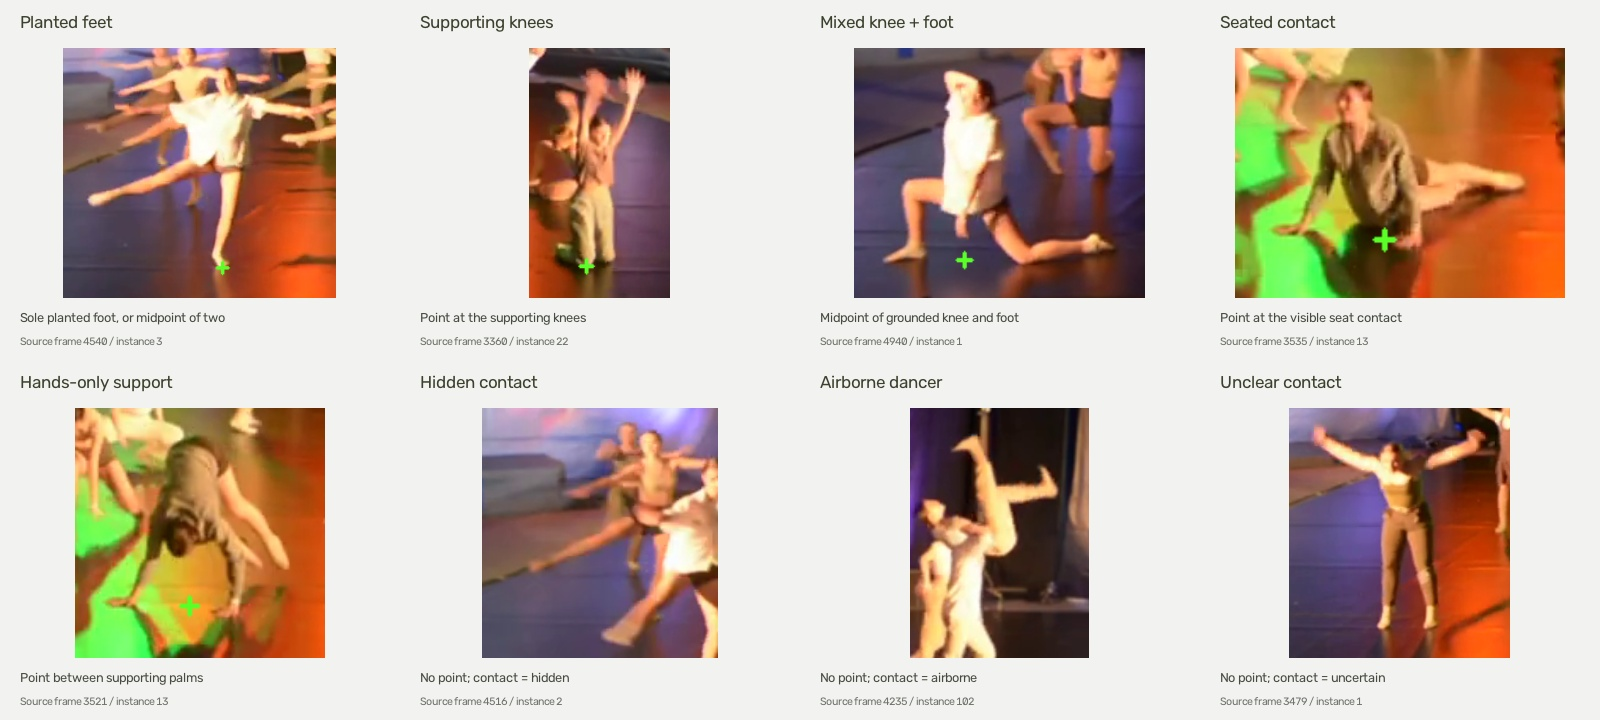

In [2]:
show(early / 'figures/label_examples.jpg')

## Keep the ID and split

Match the point's positive image-local ID to its box. Mark hidden, airborne and uncertain on the box and leave the point absent. Floor guides describe the stage, so leave them with the frame. Export **CVAT for images 1.1**. Preserve the original exports and record reviewer, date, changed labels and open cases. Use the supplied script to recreate any pack.

In [3]:
qa = load(trial / 'structural_qa.json')
for label, part in qa['parts'].items():
    print(f"Pack {label}: {part['frames']} images, {part['dancer_boxes']} boxes, {part['support_points']} points")
print('Build review ZIPs: python tools/build_300_packs.py')

Pack A: 100 images, 1830 boxes, 1331 points
Pack B: 100 images, 1821 boxes, 1360 points
Pack C: 100 images, 1808 boxes, 1377 points
Build review ZIPs: python tools/build_300_packs.py
